## Example of opening a SWOT L2 SSH EXPERT Icechunk v2 store out-of-cloud

#### Python environment

icechunk == 2.1.2
xarray == 2026.7.0
earthaccess == 0.18.0
zarr == 3.2.1

In [1]:
!pip install "icechunk==2.1.2"

  Using cached icechunk-2.1.2-cp312-abi3-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (12 kB)
Using cached icechunk-2.1.2-cp312-abi3-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (17.1 MB)


In [2]:
!pip list | grep -E "icec|^xarray|earth|^zarr"

earthaccess                   0.18.0
icechunk                      2.1.2
xarray                        2026.4.0
zarr                          3.2.1


In [3]:
import icechunk
import xarray as xr
import earthaccess
import os
import numpy as np

#  mapping
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

In [4]:
# --- 1. Fetch OPS Credentials for the Underlying Data Files ---
# Make sure we are pointing to Production (OPS) first
os.environ.pop("EARTHDATA_ENV", None)
earthaccess.login() # Logs into production URS

# 1a. Search for the SWOT L2 Expert collection to get granule metadata
results = earthaccess.search_data(
    short_name="SWOT_L2_LR_SSH_EXPERT_D",
    count=1
)

# 1b. Pass `results` so earthaccess finds the unique SWOT S3 credential endpoint
ops_creds = earthaccess.get_s3_credentials(results=results)

# --- 2. Fetch  Credentials for the Icechunk VDS Repository in UAT or OPS ---
#auth = earthaccess.login()
auth = earthaccess.login(system=earthaccess.UAT)

# Get temporary credentials from the PODAAC UAT/OPS endpoint
ice_creds = auth.get_s3_credentials(
    daac="PODAAC",
    #endpoint="https://archive.podaac.earthdata.nasa.gov/s3credentials"\
    endpoint="https://archive.podaac.uat.earthdata.nasa.gov/s3credentials"
)

# --- 3. Configure the Virtual Credentials for the Actual Data (OPS) ---
edl_virtual_creds = icechunk.s3_static_credentials(
    access_key_id=ops_creds["accessKeyId"],
    secret_access_key=ops_creds["secretAccessKey"],
    session_token=ops_creds["sessionToken"]
)

# Map the OPS protected bucket to the OPS credentials we fetched in step 1
auth_map = icechunk.containers_credentials({
    #"s3://podaac-ops-cumulus-protected/": edl_virtual_creds
    "s3://podaac-swot-ops-cumulus-protected/" : edl_virtual_creds
})

# --- 4. Configure Storage for Icechunk Metadata (UAT/OPS) ---
# Give the OPS public bucket the OPS credentials we fetched in step 2
storage = icechunk.s3_storage(
    bucket="podaac-uat-cumulus-public",
    #prefix="virtual_collections/ECCO_L4_SSH_05DEG_DAILY_V4R4B/ECCO_L4_SSH_05DEG_DAILY_V4R4B.icechunk_v2.s3",
    #prefix="virtual_collections/MUR25-JPL-L4-GLOB-v04.2/MUR25-JPL-L4-GLOB-v04.2.icechunk_v2.s3",
    prefix="virtual_collections/SWOT_L2_LR_SSH_Expert_D/SWOT_L2_LR_SSH_Expert_D.icechunk_v2.s3",
    access_key_id=ice_creds['accessKeyId'],
    secret_access_key=ice_creds['secretAccessKey'],
    session_token=ice_creds['sessionToken']
)

# --- 5. Open Repo and Load Data ---
# This merges both environments seamlessly
repo = icechunk.Repository.open(
    storage,
    authorize_virtual_chunk_access=auth_map
)

session = repo.readonly_session("main")
ds = xr.open_zarr(session.store, consolidated=False)

print("Successfully loaded dataset in-cloud!")
print(ds)

/srv/conda/envs/notebook/lib/python3.13/site-packages/earthaccess/results.py:348: FutureWarning: As of version 1.0, `DataGranule.size` will be accessed as an attribute; e.g. use `DataCollection.size` **not** `DataCollection.size()`
  self["size"] = self.size()


Successfully loaded cross-environment dataset!
<xarray.Dataset> Size: 11TB
Dimensions:                                (granule: 27010, num_lines: 9866,
                                            num_pixels: 69, num_sides: 2)
Coordinates:
  * granule                                (granule) int64 216kB 0 1 ... 27009
    cycle                                  (granule) int64 216kB dask.array<chunksize=(27010,), meta=np.ndarray>
    filename                               (granule) <U72 8MB dask.array<chunksize=(1689,), meta=np.ndarray>
    ppass                                  (granule) int64 216kB dask.array<chunksize=(27010,), meta=np.ndarray>
    orbit                                  (granule) datetime64[ns] 216kB dask.array<chunksize=(27010,), meta=np.ndarray>
    latitude_nadir                         (num_lines) float64 79kB dask.array<chunksize=(9866,), meta=np.ndarray>
    longitude_nadir                        (num_lines) float64 79kB dask.array<chunksize=(9866,), meta=np.ndar

In [5]:
# Do a CMR granule search and find the orbits in a specific space/time window. SWOT is 0-360 in longitude.
# This bbox for Indian/Southern Ocean
lat_min, lat_max = -80, 20
lon_min, lon_max = 0, 120

start_time = '2025-05-10T00:28:00'
end_time = '2025-05-10T23:28:00'

short_name = 'SWOT_L2_LR_SSH_EXPERT_D'

# why authorize again ??
earthaccess.login()

granule_result = earthaccess.search_data(
    short_name=short_name,
    temporal=(start_time, end_time),
    bounding_box=(lon_min, lat_min, lon_max, lat_max)
)
print(len(granule_result))


14


/srv/conda/envs/notebook/lib/python3.13/site-packages/earthaccess/results.py:348: FutureWarning: As of version 1.0, `DataGranule.size` will be accessed as an attribute; e.g. use `DataCollection.size` **not** `DataCollection.size()`
  self["size"] = self.size()


In [6]:
# Get granule start times from CMR granule search result. Will be used to subset into the VDS:
datetimes_str = [g['umm']['TemporalExtent']['RangeDateTime']['BeginningDateTime'][:-1] for g in granule_result]  # -1 to remove "Z" at end.
datetimes_obj = [np.datetime64(dts) for dts in datetimes_str]
#print(datetimes_obj)

In [7]:
# Mask (and subset)the entire VDS with the orbits found from the CMR space/time query and granule metadata parsing for start times
mask = ds.orbit.isin(datetimes_obj).compute()
data_vds_subset = ds.where(mask, drop=True)
data_vds_subset

<xarray.Dataset> Size: 6GB
Dimensions:                                (granule: 14, num_lines: 9866,
                                            num_pixels: 69, num_sides: 2)
Coordinates:
  * granule                                (granule) int64 112B 16570 ... 16588
    cycle                                  (granule) int64 112B 32 32 ... 32 32
    filename                               (granule) <U72 4kB 'SWOT_L2_LR_SSH...
    ppass                                  (granule) int64 112B 340 342 ... 361
    orbit                                  (granule) datetime64[ns] 112B 2025...
    latitude_nadir                         (num_lines) float64 79kB dask.array<chunksize=(9866,), meta=np.ndarray>
    longitude_nadir                        (num_lines) float64 79kB dask.array<chunksize=(9866,), meta=np.ndarray>
    latitude                               (granule, num_lines, num_pixels) float64 76MB dask.array<chunksize=(1, 9866, 69), meta=np.ndarray>
    longitude                              (granule, num_lines, num_pixels) float64 76MB dask.array<chunksize=(1, 9866, 69), meta=np.ndarray>
Dimensions without coordinates: num_lines, num_pixels, num_sides
Data variables: (12/98)
    doppler_centroid                       (granule, num_lines, num_pixels) float64 76MB dask.array<chunksize=(1, 9866, 69), meta=np.ndarray>
    cross_track_angle                      (granule, num_lines) float64 1MB dask.array<chunksize=(1, 9866), meta=np.ndarray>
    dynamic_ice_flag                       (granule, num_lines, num_pixels) float32 38MB dask.array<chunksize=(1, 9866, 69), meta=np.ndarray>
    distance_to_coast                      (granule, num_lines, num_pixels) float64 76MB dask.array<chunksize=(1, 9866, 69), meta=np.ndarray>
    ancillary_surface_classification_flag  (granule, num_lines, num_pixels) float32 38MB dask.array<chunksize=(1, 9866, 69), meta=np.ndarray>
    depth_or_elevation                     (granule, num_lines, num_pixels) float64 76MB dask.array<chunksize=(1, 9866, 69), meta=np.ndarray>
    ...                                     ...
    wind_speed_ssb_cor_source              (granule, num_lines, num_pixels) float32 38MB dask.array<chunksize=(1, 9866, 69), meta=np.ndarray>
    x_factor                               (granule, num_lines, num_pixels) float32 38MB dask.array<chunksize=(1, 9866, 69), meta=np.ndarray>
    swh_ssb_cor_source_2                   (granule, num_lines, num_pixels) float32 38MB dask.array<chunksize=(1, 9866, 69), meta=np.ndarray>
    wind_speed_ssb_cor_source_2            (granule, num_lines, num_pixels) float32 38MB dask.array<chunksize=(1, 9866, 69), meta=np.ndarray>
    wind_speed_karin                       (granule, num_lines, num_pixels) float64 76MB dask.array<chunksize=(1, 9866, 69), meta=np.ndarray>
    wind_speed_rad                         (granule, num_lines, num_sides) float64 2MB dask.array<chunksize=(1, 9866, 2), meta=np.ndarray>
Attributes: (12/22)
    Conventions:                      CF-1.7
    title:                            Level 2 Low Rate Sea Surface Height Dat...
    institution:                      CNES
    source:                           Ka-band radar interferometer
    platform:                         SWOT
    reference_document:               D-56407_SWOT_Product_Description_L2_LR_SSH
    ...                               ...
    xref_param_l2_lr_precalssh_file:  SWOT_Param_L2_LR_PreCalSSH_20000101T000...
    xref_reforbittrack_files:         SWOT_RefOrbitTrack125mPass1_Nom_2000010...
    xref_geco_database_version:       v107
    ellipsoid_semi_major_axis:        6378137.0
    ellipsoid_flattening:             0.0033528106647474805
    references:                       V1.4.1

In [8]:
# Perform SSH variable maskings for the large numeric  "fill_values" and other assignments
ssh = data_vds_subset.ssh_karin.load()
ssh = ssh.where(ssh < 1000)

lat = data_vds_subset.latitude
lon = data_vds_subset.longitude

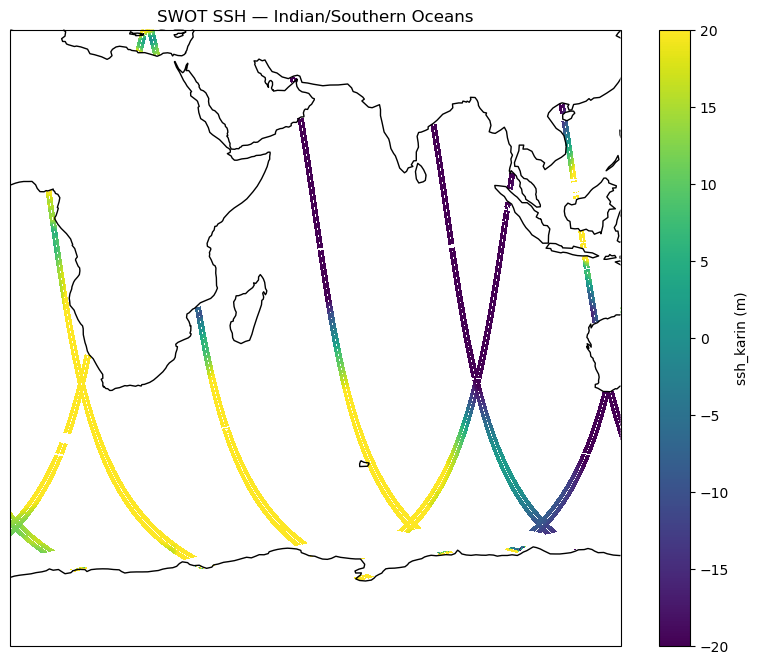

CPU times: user 13.2 s, sys: 834 ms, total: 14.1 s
Wall time: 16.5 s


In [9]:
%%time

fig = plt.figure(figsize=(10, 8))
ax = plt.axes(projection=ccrs.PlateCarree())

ax.set_extent([lon_min, lon_max, lat_min, lat_max])
ax.coastlines()

for k in range(ssh.sizes["granule"]):
    ssh_i = ssh.isel(granule=k)
    lat_i = lat.isel(granule=k)
    lon_i = lon.isel(granule=k)
    
    pcm = ax.pcolormesh(
        lon_i,
        lat_i,
        ssh_i,
        shading="auto",
        cmap="viridis",
        vmin=-20,
        vmax=20,
        transform=ccrs.PlateCarree()
    )

plt.colorbar(pcm, ax=ax, label="ssh_karin (m)")
plt.title("SWOT SSH — Indian/Southern Oceans")
plt.show()